# L14 — Transfer Learning: Don't Start from Scratch — Follow-Along Examples
**MCS 3950 Computer Vision · UPEI · Fall 2026**

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/andrewgodbout/MCS-3950-F26/blob/main/Notebooks/L14-transfer/L14_Transfer_Learning.ipynb)

This notebook accompanies **Lecture 14**. In AL7 you trained a CNN from scratch on 10,000
CIFAR-10 photos and reached about 77%. Your project will not have 10,000 labelled images. Today:
start from a **ResNet-18 that has already been trained** on 1.2 million ImageNet photos, and
reuse what it learned.

1. **A trained network's features transfer.** Its first layer has learned edge and colour
   filters (L4); its last layer gives 512 numbers per image that already sort photos by content,
   even 1958 air photos it has never seen.
2. **Two ways to reuse it.** *Feature extraction*: freeze the network, train only a new last
   layer. *Fine-tuning*: start from the trained weights and train everything a little, with a
   small learning rate.
3. **Small data.** With few labels a network memorises. Augmentation and regularisation
   (weight decay, early stopping) push back.

Data: the same CIFAR-10 slice as AL7 (`AL7_cifar10.npz`) and the twenty 1958 frames (`AL5.zip`).
The trained weights (47 MB) are downloaded once. CPU: about 8 minutes, most of it in §6–§7;
Colab with a T4 GPU: about 2 minutes, and §7c (fine-tuning on all 10,000 photos) runs only on a GPU.

| Section | Topic |
|---------|-------|
| 0 | Setup, data and the trained ResNet-18 |
| 1 | What the first layer learned |
| 2 | The network as a feature extractor |
| 3 | Features vs pixels: PCA and nearest neighbours |
| 4 | Search 1958 air photos by features |
| 5 | Recipe 1: feature extraction (a new last layer) |
| 6 | Baseline: AL7's network from scratch |
| 7 | Recipe 2: fine-tuning |
| 8 | All three side by side |
| 9 | Small data: over-fitting, weight decay, early stopping |
| 10 | Augmentation for air photos |
| 11 | The recipe for AL8 and your project |
| 12 | Try at home |

In [2]:
import io, os, time, urllib.request, zipfile
import cv2
import numpy as np
import matplotlib.pyplot as plt
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision

plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 11})
GOLD, RED, TEAL, GREEN, NAVY, PURPLE, GREY = ("#C8962C", "#B82828", "#1A7A8A", "#2E7D50",
                                              "#1A3A5C", "#7B4EA0", "#7A8FA6")
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
if DEVICE == "cpu":
    torch.set_num_threads(2)
print("PyTorch", torch.__version__, "| torchvision", torchvision.__version__, "| device", DEVICE)

def n_params(model, trainable_only=False):
    return sum(p.numel() for p in model.parameters() if p.requires_grad or not trainable_only)

PyTorch 2.15.0+cu132 | torchvision 0.29.2+cu132 | device cpu


## 0 · Setup, data and the trained ResNet-18

**CIFAR-10 slice** from AL7: train 10,000 (1,000 per class), val 2,000, test 2,000.
**AL5.zip**: twenty 1958 frames of PEI (about 3.5 m per pixel).

In [3]:
BASE = ("https://raw.githubusercontent.com/andrewgodbout/"
        "MCS-3950-F26/main/Notebooks/data/")

def fetch(name, needed, unzip=False):
    if all(os.path.exists(f) for f in needed):
        print(f"{name}: already present"); return
    with urllib.request.urlopen(BASE + name, timeout=180) as r:
        blob = r.read()
    if unzip:
        with zipfile.ZipFile(io.BytesIO(blob)) as z:
            z.extractall(".")
    else:
        with open(name, "wb") as f:
            f.write(blob)
    print(f"{name}: {len(blob)/1e6:.1f} MB downloaded")

fetch("AL7_cifar10.npz", ["AL7_cifar10.npz"])
fetch("AL5.zip", ["frames/16046-19.jpg"], unzip=True)

D = np.load("AL7_cifar10.npz")
CLASSES = [str(c) for c in D["classes"]]
y_train, y_val, y_test = D["y_train"].astype(int), D["y_val"].astype(int), D["y_test"].astype(int)
print({k: D[k].shape for k in ("x_train", "x_val", "x_test")})
print("classes:", ", ".join(CLASSES))

AL7_cifar10.npz: already present
AL5.zip: already present


{'x_train': (10000, 32, 32, 3), 'x_val': (2000, 32, 32, 3), 'x_test': (2000, 32, 32, 3)}
classes: airplane, automobile, bird, cat, deer, dog, frog, horse, ship, truck


### The trained network

`torchvision.models.resnet18` is the network from L13 (four stages of residual blocks, global
average pooling, one fully connected layer to 1,000 ImageNet classes). We load **trained**
weights into it.

On your own projects the usual one line is

```python
model = torchvision.models.resnet18(weights="IMAGENET1K_V1")
```

which downloads PyTorch's own ImageNet weights. This notebook loads a different trained copy
of the *same* network (the `timm` library's ResNet-18, 71% top-1 on ImageNet, hosted on GitHub),
so that the numbers below match the lecture slides exactly. Either set of weights works for
everything here; the numbers move by a point or two.

In [4]:
WEIGHTS_URL = ("https://github.com/huggingface/pytorch-image-models/releases/download/"
               "v0.1-rsb-weights/resnet18_a1_0-d63eafa0.pth")
STATE = torch.hub.load_state_dict_from_url(WEIGHTS_URL, map_location="cpu", progress=False)

def pretrained_resnet18():
    m = torchvision.models.resnet18(weights=None)        # the L13 architecture ...
    m.load_state_dict(STATE)                              # ... with ImageNet-trained weights
    return m

net = pretrained_resnet18()
print(f"ResNet-18: {n_params(net):,d} parameters")
print(f"  last layer (fc): {net.fc.in_features} x {net.fc.out_features} + {net.fc.out_features}"
      f" = {n_params(net.fc):,d}")
print(f"  everything before it (the 'body'): {n_params(net) - n_params(net.fc):,d}")

ResNet-18: 11,689,512 parameters
  last layer (fc): 512 x 1000 + 1000 = 513,000
  everything before it (the 'body'): 11,176,512


### From a 32 × 32 CIFAR photo to the network's input

ImageNet photos are about 224 × 224. CIFAR's are 32 × 32: a ResNet trained on big photos sees
almost nothing in them. We **enlarge** each image to 112 × 112 (a compromise: 224 would be a
bit more accurate and four times slower) and normalise each colour channel with ImageNet's
mean and standard deviation, the numbers the network was trained with (L9's centring again).

In [5]:
SIZE = 112
IMNET_MEAN = torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1)
IMNET_STD = torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1)

def prep(x_uint8):
    # (N, H, W, 3) uint8 (or (N, H, W) grey) -> (N, 3, SIZE, SIZE) normalised float tensor on DEVICE
    x = torch.as_tensor(x_uint8).float().div(255)
    if x.ndim == 3:                                        # grey air photo: copy it into R, G and B
        x = x[..., None].expand(-1, -1, -1, 3)
    x = x.permute(0, 3, 1, 2)
    x = F.interpolate(x, size=SIZE, mode="bilinear", align_corners=False)
    return ((x - IMNET_MEAN) / IMNET_STD).to(DEVICE)

print(prep(D["x_train"][:4]).shape)

torch.Size([4, 3, 112, 112])


## 1 · What the first layer learned

`conv1` has 64 filters, each 7 × 7 × 3 (L12's formula: 64 × 7 × 7 × 3 = 9,408 weights, no bias
because batch norm follows). Below: the 64 filters **before** training (random) and **after**
training on ImageNet, each shown as a small colour image.

The trained ones are edge detectors at every angle (L4's Sobel, learned), stripes (texture), and
colour blobs. Nobody designed them: they fell out of training on 1.2 million photos, and they are
useful for **any** photo. That is why transfer works.

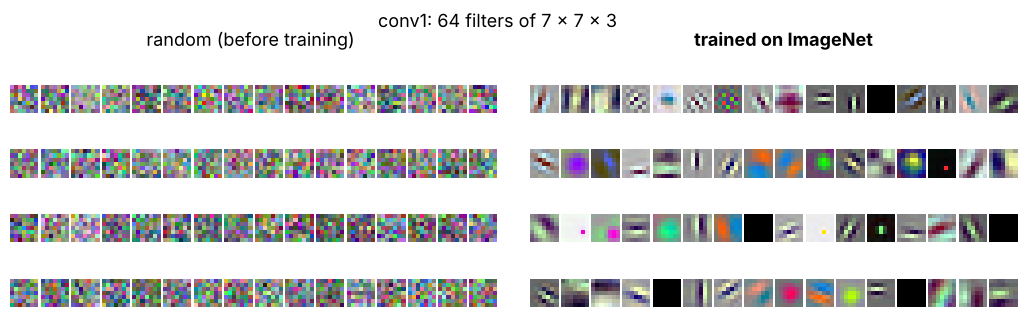

In [6]:
def show_filters(w, ax_grid):
    w = w.detach().cpu()
    for a, f in zip(ax_grid.ravel(), w):
        f = (f - f.min()) / (f.max() - f.min() + 1e-8)   # each filter stretched to 0..1 for display
        a.imshow(f.permute(1, 2, 0), interpolation="nearest"); a.axis("off")

torch.manual_seed(0)
random_net = torchvision.models.resnet18(weights=None)
fig, axes = plt.subplots(4, 33, figsize=(13, 3.3), gridspec_kw={"wspace": 0.08, "hspace": 0.08})
for a in axes[:, 16]:
    a.axis("off")                                          # gap column between the two panels
show_filters(random_net.conv1.weight, axes[:, :16])
show_filters(net.conv1.weight, axes[:, 17:])
fig.text(0.31, 0.95, "random (before training)", ha="center", fontsize=13)
fig.text(0.72, 0.95, "trained on ImageNet", ha="center", fontsize=13, fontweight="bold")
fig.suptitle("conv1: 64 filters of 7 × 7 × 3", y=1.06, fontsize=13)
plt.show()

## 2 · The network as a feature extractor

Replace the last layer (`fc`, 512 → 1,000 ImageNet scores) with "do nothing" (`nn.Identity`).
What comes out is the 512 numbers after global average pooling (L13 slide 20): one **feature
vector** per image. Each number is one channel's average response over the whole image.

Shapes for a 112 × 112 input (224 would give 7 × 7 at the end instead of 4 × 4; GAP doesn't care):

In [7]:
body = pretrained_resnet18()
body.fc = nn.Identity()                  # cut off the ImageNet classifier
body = body.to(DEVICE).eval()            # eval: use batch norm's saved averages (L13 slide 18)

x = prep(D["x_train"][:1])
with torch.no_grad():
    print(f"{'input':10s} {tuple(x.shape[1:])}")
    x = body.maxpool(body.relu(body.bn1(body.conv1(x)))); print(f"{'stem':10s} {tuple(x.shape[1:])}")
    for name in ("layer1", "layer2", "layer3", "layer4"):
        x = getattr(body, name)(x); print(f"{name:10s} {tuple(x.shape[1:])}")
    x = body.avgpool(x).flatten(1); print(f"{'GAP':10s} {tuple(x.shape[1:])}   <- the feature vector")

input      (3, 112, 112)
stem       (64, 28, 28)
layer1     (64, 28, 28)
layer2     (128, 14, 14)
layer3     (256, 7, 7)
layer4     (512, 4, 4)
GAP        (512,)   <- the feature vector


Now compute the feature vector of **every** image once and keep it. Everything in §3–§5 and §9
then works on 512 numbers per image instead of running the network again. (CPU: about a minute
for 14,000 images.)

In [8]:
def features(x_uint8, bs=200):
    out = []
    with torch.no_grad():
        for i in range(0, len(x_uint8), bs):
            out.append(body(prep(x_uint8[i:i + bs])).cpu())
    return torch.cat(out)

t0 = time.time()
f_train, f_val, f_test = (features(D[k]) for k in ("x_train", "x_val", "x_test"))
print(f"features: train {tuple(f_train.shape)}, val {tuple(f_val.shape)}, test {tuple(f_test.shape)}"
      f"  ({time.time() - t0:.0f} s)")

features: train (10000, 512), val (2000, 512), test (2000, 512)  (78 s)


## 3 · Features vs pixels: PCA and nearest neighbours

**PCA (L9).** Take test photos of three classes and project them onto their first two principal
components, once using the raw pixels (32 × 32 × 3 = 3,072 numbers) and once using the 512
features. In pixel space the classes sit on top of each other: PC1 is mostly overall brightness
(as in A1). In feature space they separate, although PCA never saw a label and ResNet-18 never
saw CIFAR.

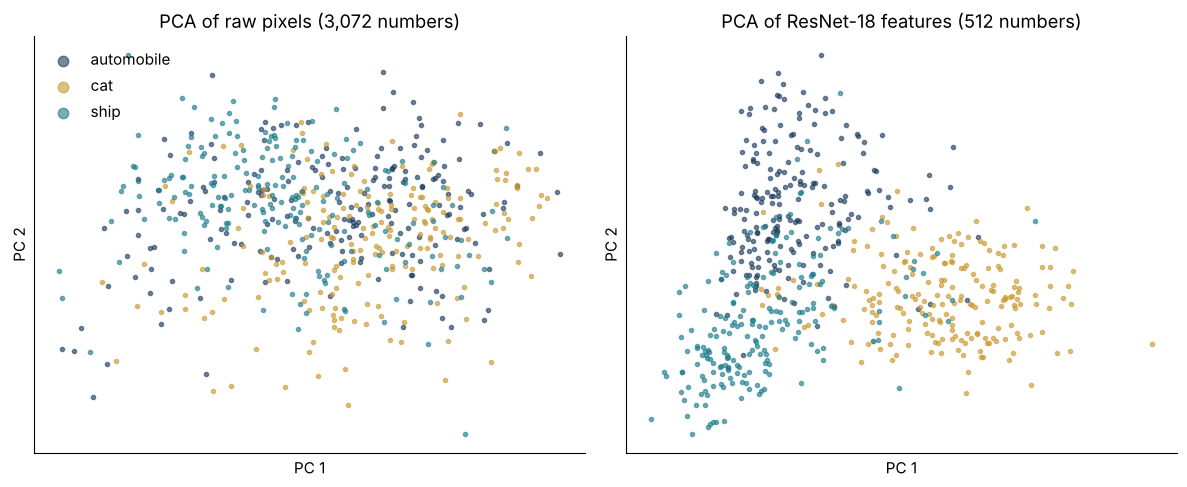

In [9]:
def pca2(X):
    X = X - X.mean(0)                                     # centre (L9)
    U, S, Vt = np.linalg.svd(X, full_matrices=False)
    return X @ Vt[:2].T

SHOW = [CLASSES.index(c) for c in ("automobile", "cat", "ship")]
sel = np.isin(y_test, SHOW)
pix = D["x_test"][sel].reshape(sel.sum(), -1).astype(np.float32) / 255
fea = f_test[sel].numpy()
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, X) in zip(axes, [("raw pixels (3,072 numbers)", pix), ("ResNet-18 features (512 numbers)", fea)]):
    Z = pca2(X)
    for c, col in zip(SHOW, [NAVY, GOLD, TEAL]):
        m = y_test[sel] == c
        ax.scatter(Z[m, 0], Z[m, 1], s=9, alpha=0.6, color=col, label=CLASSES[c])
    ax.set_title(f"PCA of {title}"); ax.set_xlabel("PC 1"); ax.set_ylabel("PC 2")
    ax.set_xticks([]); ax.set_yticks([])
axes[0].legend(markerscale=2.5, frameon=False)
plt.tight_layout(); plt.show()

**Nearest neighbours.** For a test photo, find the five training photos closest to it (smallest
Euclidean distance), using pixels or features. Then the same thing as a classifier: give each
test photo the label of its single nearest neighbour among 100 labelled photos per class
(1-nearest-neighbour; no training at all).

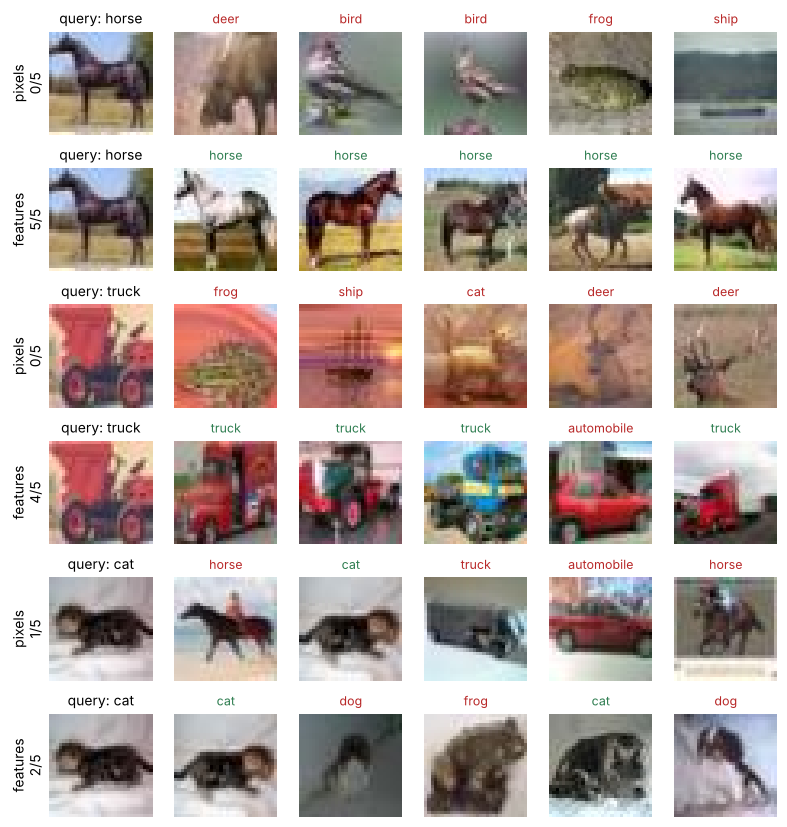

5 nearest by pixels  : on average 1.3 of 5 share the test photo's class
5 nearest by features: on average 2.7 of 5 share the test photo's class


1-nearest-neighbour on pixels   (100 labelled photos per class): 24.9% of test correct
1-nearest-neighbour on features (100 labelled photos per class): 52.2% of test correct


In [10]:
def nearest(q, bank, k=5):
    d = ((bank - q[None]) ** 2).sum(1)
    return np.argsort(d)[:k]

pix_train = D["x_train"].reshape(len(y_train), -1).astype(np.float32) / 255
pix_test = D["x_test"].reshape(len(y_test), -1).astype(np.float32) / 255
# the first horse and the first truck in the test set, and the 4th cat (cats are the hardest class)
QUERIES = [int(np.where(y_test == CLASSES.index(c))[0][i]) for c, i in (("horse", 0), ("truck", 0), ("cat", 3))]

fig, axes = plt.subplots(len(QUERIES) * 2, 6, figsize=(9.6, 10.2), gridspec_kw={"hspace": 0.32, "wspace": 0.05})
for r, q in enumerate(QUERIES):
    for rr, (lab, bank, qv) in enumerate([("pixels", pix_train, pix_test[q]),
                                          ("features", f_train.numpy(), f_test[q].numpy())]):
        row = axes[2 * r + rr]
        nn_idx = nearest(qv, bank)
        row[0].imshow(D["x_test"][q]); row[0].set_title(f"query: {CLASSES[y_test[q]]}", fontsize=10)
        hits = 0
        for a, j in zip(row[1:], nn_idx):
            ok = y_train[j] == y_test[q]; hits += ok
            a.imshow(D["x_train"][j]); a.set_title(CLASSES[y_train[j]], fontsize=9, color=GREEN if ok else RED)
        row[0].set_ylabel(f"{lab}\n{hits}/5", fontsize=10)
        for a in row:
            a.set_xticks([]); a.set_yticks([])
            for s in a.spines.values(): s.set_visible(False)
plt.show()

# the same count over all 2,000 test photos, so the three examples above can be judged fairly
for lab, bank, test in [("pixels", pix_train, pix_test), ("features", f_train.numpy(), f_test.numpy())]:
    nn5 = torch.cdist(torch.tensor(test), torch.tensor(bank)).topk(5, largest=False).indices.numpy()
    print(f"5 nearest by {lab:8s}: on average {(y_train[nn5] == y_test[:, None]).sum(1).mean():.1f} of 5 share the test photo's class")

rng = np.random.default_rng(0)
ref = np.concatenate([rng.permutation(np.where(y_train == c)[0])[:100] for c in range(10)])
for lab, bank, test in [("pixels", pix_train, pix_test), ("features", f_train.numpy(), f_test.numpy())]:
    B = torch.tensor(bank[ref]); T = torch.tensor(test)
    pred = y_train[ref][torch.cdist(T, B).argmin(1).numpy()]
    print(f"1-nearest-neighbour on {lab:8s} (100 labelled photos per class): {(pred == y_test).mean():.1%} of test correct")

## 4 · Search 1958 air photos by features

ImageNet has no 1958 air photos: no grey, top-down farmland. Does the network still describe
them usefully? Cut the twenty AL5 frames into 80 × 80 pixel tiles (about 280 m on a side;
the 50-pixel border with the frame's fiducial marks is skipped), copy each grey tile into R, G
and B, and compute its 512 features. Then pick a tile from frame 16046-19 and find its nearest
tiles in the **other 19 frames**. No labels anywhere.

(Frames 16046-18 and -20 overlap 16046-19, so the same piece of ground can show up as a
neighbour. That's fine: it's the right answer.)

In [11]:
import glob
T, M = 80, 50
tiles, where = [], []
for path in sorted(glob.glob("frames/*.jpg")):
    im = cv2.imread(path, cv2.IMREAD_GRAYSCALE)
    name = os.path.basename(path)[:-4]
    for r in range((im.shape[0] - 2 * M) // T):
        for c in range((im.shape[1] - 2 * M) // T):
            tiles.append(im[M + r * T: M + (r + 1) * T, M + c * T: M + (c + 1) * T]); where.append((name, r, c))
tiles = np.stack(tiles)
f_tiles = features(tiles).numpy()
print(f"{len(tiles)} tiles from 20 frames -> features {f_tiles.shape}")

2200 tiles from 20 frames -> features (2200, 512)


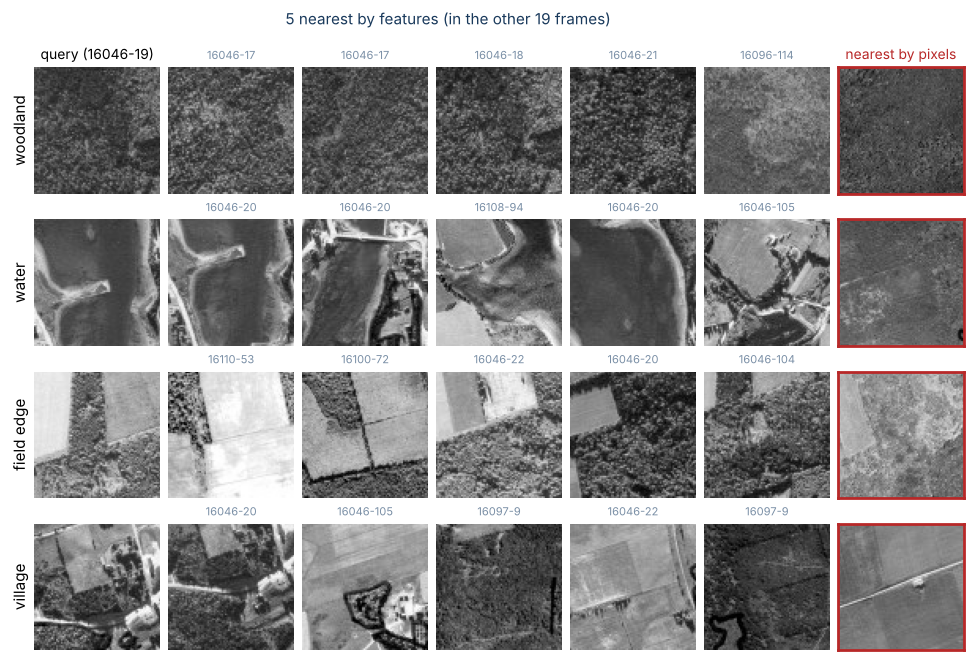

In [12]:
QUERY_TILES = [("16046-19", 0, 1, "woodland"), ("16046-19", 1, 7, "water"),
               ("16046-19", 7, 9, "field edge"), ("16046-19", 2, 6, "village")]
names = np.array([w[0] for w in where])
fig, axes = plt.subplots(len(QUERY_TILES), 7, figsize=(12, 7.6), gridspec_kw={"wspace": 0.06, "hspace": 0.18})
for row, (fr, r, c, lab) in zip(axes, QUERY_TILES):
    q = where.index((fr, r, c))
    others = np.where(names != fr)[0]                     # search the other 19 frames only
    nn_idx = others[nearest(f_tiles[q], f_tiles[others], k=5)]
    pix_nn = others[nearest(tiles[q].astype(np.float32).ravel(),
                            tiles[others].reshape(len(others), -1).astype(np.float32), k=1)]
    row[0].imshow(tiles[q], cmap="gray", vmin=0, vmax=255); row[0].set_ylabel(lab, fontsize=11)
    for a, j in zip(row[1:6], nn_idx):
        a.imshow(tiles[j], cmap="gray", vmin=0, vmax=255)
        a.set_title(where[j][0], fontsize=8, color=GREY)
    row[6].imshow(tiles[pix_nn[0]], cmap="gray", vmin=0, vmax=255)
    for a in row:
        a.set_xticks([]); a.set_yticks([])
        for s in a.spines.values(): s.set_visible(False)
    for s in row[6].spines.values(): s.set_visible(True); s.set_color(RED); s.set_linewidth(2)
axes[0, 0].set_title("query (16046-19)", fontsize=10)
fig.text(0.47, 0.935, "5 nearest by features (in the other 19 frames)", ha="center", fontsize=11, color=NAVY)
axes[0, 6].set_title("nearest by pixels", fontsize=10, color=RED)
plt.show()

## 5 · Recipe 1: feature extraction (a new last layer)

Freeze everything the network learned; replace `fc` with a new layer for **our** 10 classes and
train only that. With the features already computed (§2), "training the new layer" is
L12's softmax classifier on 512 numbers per image: seconds, even on a CPU.

The whole recipe in PyTorch, for reference:

```python
model = pretrained_resnet18()
for p in model.parameters():
    p.requires_grad = False              # freeze: no gradient, no update
model.fc = nn.Linear(512, 10)            # new last layer: trainable by default
```

In [13]:
model = pretrained_resnet18()
for p in model.parameters():
    p.requires_grad = False
model.fc = nn.Linear(512, 10)
print(f"trainable: {n_params(model, True):,d} of {n_params(model):,d}"
      f"  ({n_params(model, True) / n_params(model):.3%})")
print(f"by hand:   512 x 10 + 10 = {512 * 10 + 10:,d}")

trainable: 5,130 of 11,181,642  (0.046%)
by hand:   512 x 10 + 10 = 5,130


How many labelled photos do we need? Take the first **n per class** from a fixed shuffle of the
training set (n = 10, 50, 100, 1,000) and train the new layer on their features: Adam, full batch,
300 steps, a little weight decay (§9). Test on the same 2,000 test photos as AL7.

In [14]:
rng = np.random.default_rng(0)
ORDER = [rng.permutation(np.where(y_train == c)[0]) for c in range(10)]
def subset(n):                       # first n of each class from a fixed shuffle: 10 is inside 50 is inside 100 ...
    return np.concatenate([o[:n] for o in ORDER])

def train_head(f, y, steps=300, lr=0.01, wd=1e-3, f_eval=None, y_eval=None, seed=0):
    '''Softmax classifier (one nn.Linear) on fixed features. Returns the layer and, if f_eval is given,
    a history of (train accuracy, eval accuracy) after every step.'''
    torch.manual_seed(seed)
    head = nn.Linear(f.shape[1], 10)
    opt = torch.optim.Adam(head.parameters(), lr=lr, weight_decay=wd)
    y = torch.as_tensor(y); hist = []
    for _ in range(steps):
        loss = F.cross_entropy(head(f), y)
        opt.zero_grad(); loss.backward(); opt.step()
        if f_eval is not None:
            with torch.no_grad():
                hist.append(((head(f).argmax(1) == y).float().mean().item(),
                             (head(f_eval).argmax(1).numpy() == y_eval).mean()))
    return head, hist

def head_acc(head, f, y):
    with torch.no_grad():
        return (head(f).argmax(1).numpy() == y).mean()

NS = [10, 50, 100, 1000]
RESULTS = {"feature extraction": {}, "fine-tuning": {}, "from scratch": {}}
HEADS = {}
for n in NS:
    idx = subset(n)
    HEADS[n], _ = train_head(f_train[idx], y_train[idx])
    RESULTS["feature extraction"][n] = head_acc(HEADS[n], f_test, y_test)
    print(f"n = {n:4d} per class ({10 * n:5d} photos): test accuracy {RESULTS['feature extraction'][n]:.1%}")

n =   10 per class (  100 photos): test accuracy 53.8%


n =   50 per class (  500 photos): test accuracy 63.1%


n =  100 per class ( 1000 photos): test accuracy 66.7%


n = 1000 per class (10000 photos): test accuracy 73.7%


## 6 · Baseline: AL7's network from scratch

For comparison, AL7's chosen network (6 conv + batch norm, flips and shifts, learning rate 0.05
falling to 0) trained from random weights on the same small subsets, on the original 32 × 32
photos. With n = 1,000 it is exactly AL7's Part 4 run: **76.8%** on the same test set. Here we run
n = 10 and n = 100. Fewer photos means more passes over them (epochs) for a similar number of
steps. (CPU: about 4 minutes.)

In [15]:
def make_cnn(per_stage=2, bn=True, widths=(32, 64, 128)):        # AL7's make_cnn
    layers, c_in = [], 3
    for w in widths:
        for _ in range(per_stage):
            layers.append(nn.Conv2d(c_in, w, 3, padding=1))
            if bn: layers.append(nn.BatchNorm2d(w))
            layers.append(nn.ReLU()); c_in = w
        layers.append(nn.MaxPool2d(2))
    layers += [nn.AdaptiveAvgPool2d(1), nn.Flatten(), nn.Linear(c_in, 10)]
    return nn.Sequential(*layers)

def to32(x):                                                       # AL7's normalisation (its train mean / std)
    return torch.tensor(x).permute(0, 3, 1, 2).float().div(255)
MEAN32 = to32(D["x_train"]).mean((0, 2, 3), keepdim=True)
STD32 = to32(D["x_train"]).std((0, 2, 3), keepdim=True)
X32_test = ((to32(D["x_test"]) - MEAN32) / STD32).to(DEVICE)

def augment32(x, max_shift=4):                                     # AL7 Task 3: flip + shift
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    p = F.pad(x, (max_shift,) * 4, mode="reflect")
    i, j = np.random.randint(0, 2 * max_shift + 1, 2)
    return p[:, :, i:i + 32, j:j + 32]

def scratch(n, epochs, bs):
    idx = subset(n)
    X = ((to32(D["x_train"][idx]) - MEAN32) / STD32).to(DEVICE)
    Y = torch.tensor(y_train[idx]).to(DEVICE)
    torch.manual_seed(0); np.random.seed(0)
    m = make_cnn().to(DEVICE)
    opt = torch.optim.SGD(m.parameters(), lr=0.05, momentum=0.9)
    steps = epochs * ((len(X) + bs - 1) // bs)
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda k: 1 - k / steps)
    for ep in range(epochs):
        m.train(); perm = torch.randperm(len(X), device=DEVICE)
        for i in range(0, len(X), bs):
            k = perm[i:i + bs]
            loss = F.cross_entropy(m(augment32(X[k])), Y[k])
            opt.zero_grad(); loss.backward(); opt.step(); sched.step()
    m.eval()
    with torch.no_grad():
        return (m(X32_test).argmax(1).cpu().numpy() == y_test).mean()

t0 = time.time()
RESULTS["from scratch"][10] = scratch(10, epochs=300, bs=100)
RESULTS["from scratch"][100] = scratch(100, epochs=100, bs=128)
RESULTS["from scratch"][1000] = 0.768                     # AL7 Part 4 (same recipe, 25 epochs, same test set)
for n, a in RESULTS["from scratch"].items():
    print(f"from scratch, n = {n:4d} per class: {a:.1%}" + ("   (AL7)" if n == 1000 else ""))
print(f"({time.time() - t0:.0f} s)")

from scratch, n =   10 per class: 31.0%
from scratch, n =  100 per class: 55.2%
from scratch, n = 1000 per class: 76.8%   (AL7)
(195 s)


## 7 · Recipe 2: fine-tuning

Start from the trained network **and** the new last layer from §5, then let every weight move,
gently:

* **small learning rate** (0.001, fifty times AL7's 0.05): the trained weights are already good;
  big steps would wreck them (L12 slide 14: too big a step jumps right past the minimum);
* **start with a trained last layer** (§5's), not a random one, so the first, large gradients
  don't flow back into the good features;
* keep batch norm's ImageNet averages (its layers stay in `eval` mode);
* augment: flips and shifts, as in AL7.

Only a few epochs: each one now runs the whole 11-million-weight network forwards and
backwards on 112 × 112 images. (CPU: about 3 minutes for n = 10 and n = 100.)

In [16]:
def augment(x):                                            # flip + shift by up to SIZE/8 px (AL7's 4 px at 32)
    flip = torch.rand(len(x), device=x.device) < 0.5
    x = torch.where(flip[:, None, None, None], x.flip(3), x)
    s = SIZE // 8
    p = F.pad(x, (s, s, s, s), mode="reflect")
    i, j = np.random.randint(0, 2 * s + 1, 2)
    return p[:, :, i:i + SIZE, j:j + SIZE]

def freeze_bn(m):
    for mod in m.modules():
        if isinstance(mod, nn.BatchNorm2d):
            mod.eval()                                     # keep ImageNet's running averages

def accuracy(m, x_uint8, y, bs=200):
    m.eval(); hits = 0
    with torch.no_grad():
        for i in range(0, len(x_uint8), bs):
            hits += (m(prep(x_uint8[i:i + bs])).argmax(1).cpu().numpy() == y[i:i + bs]).sum()
    return hits / len(y)

def fine_tune(n, epochs, lr=0.001, bs=32, seed=0):
    idx = subset(n)
    X, Y = D["x_train"][idx], torch.tensor(y_train[idx]).to(DEVICE)
    torch.manual_seed(seed); np.random.seed(seed)
    m = pretrained_resnet18()
    m.fc = nn.Linear(512, 10)
    m.fc.load_state_dict(HEADS[n].state_dict())           # start from §5's trained last layer
    m = m.to(DEVICE)
    opt = torch.optim.SGD(m.parameters(), lr=lr, momentum=0.9)
    for ep in range(epochs):
        m.train(); freeze_bn(m)
        perm = np.random.permutation(len(X))
        for i in range(0, len(X), bs):
            k = perm[i:i + bs]
            loss = F.cross_entropy(m(augment(prep(X[k]))), Y[k])
            opt.zero_grad(); loss.backward(); opt.step()
    return m

t0 = time.time()
for n, ep in ((10, 20), (100, 6)):
    m = fine_tune(n, ep)
    RESULTS["fine-tuning"][n] = accuracy(m, D["x_test"], y_test)
    print(f"fine-tuning, n = {n:4d} per class, {ep} epochs: {RESULTS['fine-tuning'][n]:.1%}"
          f"   (feature extraction: {RESULTS['feature extraction'][n]:.1%})")
print(f"({time.time() - t0:.0f} s)")

fine-tuning, n =   10 per class, 20 epochs: 52.5%   (feature extraction: 53.8%)


fine-tuning, n =  100 per class, 6 epochs: 68.0%   (feature extraction: 66.7%)
(162 s)


### 7b · How many weights move?

A middle way is to unfreeze only the **last stage** (`layer4`) plus the new `fc`: the late,
ImageNet-specific features adapt and the early, generic ones (§1) stay as they are.

In [17]:
def count_trainable(unfreeze):
    m = pretrained_resnet18(); m.fc = nn.Linear(512, 10)
    for name, p in m.named_parameters():
        p.requires_grad = any(name.startswith(u) for u in unfreeze)
    return n_params(m, True), n_params(m)

for lab, unf in [("fc only (feature extraction)", ["fc"]), ("layer4 + fc", ["layer4", "fc"]),
                 ("everything (fine-tuning)", [""])]:
    k, tot = count_trainable(unf)
    print(f"{lab:30s} {k:12,d} trainable  ({k / tot:6.2%})")

fc only (feature extraction)          5,130 trainable  ( 0.05%)


layer4 + fc                       8,398,858 trainable  (75.11%)


everything (fine-tuning)         11,181,642 trainable  (100.00%)


### 7c · Fine-tuning with all 1,000 photos per class (GPU only)

Four epochs over 10,000 photos at 112 × 112: about a minute on a Colab T4, about 15 minutes on a
CPU. On a CPU this cell prints the result from the lecture build instead of running.

In [18]:
FT_1000_BUILD = None   # filled in below on a GPU (or when RUN_BIG is set)
RUN_BIG = DEVICE == "cuda" or os.environ.get("L14_RUN_BIG") == "1"
if RUN_BIG:
    t0 = time.time()
    m = fine_tune(1000, epochs=4)
    RESULTS["fine-tuning"][1000] = accuracy(m, D["x_test"], y_test)
    print(f"fine-tuning, n = 1000 per class, 4 epochs: {RESULTS['fine-tuning'][1000]:.1%}  ({time.time() - t0:.0f} s)")
else:
    RESULTS["fine-tuning"][1000] = 0.805                # lecture build (CPU, same code)
    print(f"no GPU: using the lecture build's result, {RESULTS['fine-tuning'][1000]:.1%}")

fine-tuning, n = 1000 per class, 4 epochs: 80.5%  (686 s)


## 8 · All three side by side

Test accuracy against the number of labelled photos per class (log scale). Read it from left to
right: the fewer labels, the bigger the head start from ImageNet.

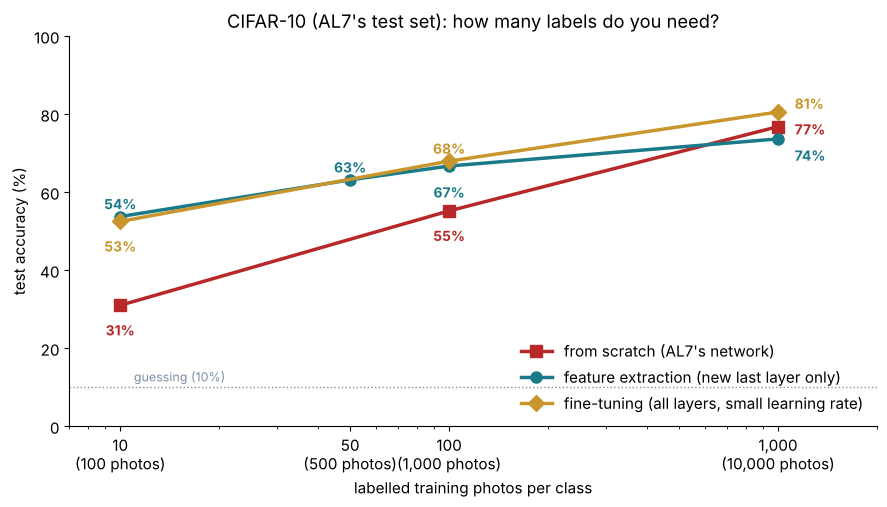

 n per class          from scratch    feature extraction           fine-tuning
          10                 31.0%                 53.8%                 52.5%
          50                     —                 63.1%                     —
         100                 55.2%                 66.7%                 68.0%
        1000                 76.8%                 73.7%                 80.5%


In [19]:
fig, ax = plt.subplots(figsize=(9, 5.2))
style = {"from scratch": (RED, "s", "from scratch (AL7's network)"),
         "feature extraction": (TEAL, "o", "feature extraction (new last layer only)"),
         "fine-tuning": (GOLD, "D", "fine-tuning (all layers, small learning rate)")}
for key, (col, mk, lab) in style.items():
    ns = sorted(RESULTS[key]); acc = [100 * RESULTS[key][n] for n in ns]
    ax.plot(ns, acc, marker=mk, color=col, lw=2.5, ms=8, label=lab)
    for n, a in zip(ns, acc):
        # label placement: (dx, dy) in points, chosen so the three lines' labels don't collide
        dx, dy = {("from scratch", 1000): (12, -2), ("feature extraction", 1000): (12, -12),
                  ("fine-tuning", 1000): (12, 6), ("fine-tuning", 10): (0, -18), ("fine-tuning", 100): (0, 9),
                  ("feature extraction", 100): (0, -19), ("from scratch", 10): (0, -18),
                  ("from scratch", 100): (0, -18)}.get((key, n), (0, 9))
        ax.annotate(f"{int(a + 0.5)}%", (n, a), textcoords="offset points", xytext=(dx, dy),
                    ha="left" if dx else "center", va="center", fontsize=10, color=col, fontweight="bold")
ax.axhline(10, color=GREY, ls=":", lw=1); ax.text(11, 11.5, "guessing (10%)", color=GREY, fontsize=9)
ax.set_xscale("log"); ax.set_xlim(7, 2000); ax.set_xticks(NS); ax.set_xticklabels([f"{n:,d}\n({10 * n:,d} photos)" for n in NS])
ax.set_xlabel("labelled training photos per class"); ax.set_ylabel("test accuracy (%)")
ax.set_ylim(0, 100); ax.legend(loc="lower right", frameon=False)
ax.set_title("CIFAR-10 (AL7's test set): how many labels do you need?")
plt.tight_layout(); plt.show()

print(f"{'n per class':>12s}" + "".join(f"{k:>22s}" for k in style))
for n in NS:
    print(f"{n:12d}" + "".join(f"{RESULTS[k][n]:22.1%}" if n in RESULTS[k] else f"{'—':>22s}" for k in style))

## 9 · Small data: over-fitting, weight decay, early stopping

With 10 photos per class the new last layer has 5,130 weights for 100 examples: it can
memorise them. Track training and **validation** accuracy (AL7's 2,000 val photos; the test set
stays untouched) at every step, for three settings of **weight decay** λ (explained below).
The dashed line marks the step with the best validation accuracy: **early stopping** would keep
the weights from that step.

Weight decay adds λ·w to every gradient, so each step also shrinks every weight a little toward 0:

  w ← w − η (g + λ w)

Big weights are how a network memorises single photos; keeping them small keeps it simple.

**What to expect here:** very little. Training reaches 100% at every λ and validation barely moves.
A new last layer on *frozen* features is already a small model (5,130 weights); freezing the other
11 million is itself the strongest regulariser. The gap that remains is not memorising that a
regulariser can undo: 100 photos simply don't show the network enough cats. Weight decay, dropout
and early stopping earn their keep when many weights move: fine-tuning and training from scratch
(AL7 Part 3: augmentation cut the train–val gap from 28 to 9 points).

λ = 0     final: train 100.0%  val  54.1%   best val 54.6% at step 55


λ = 0.01  final: train 100.0%  val  54.4%   best val 54.8% at step 36


λ = 0.1   final: train 100.0%  val  55.0%   best val 55.1% at step 79


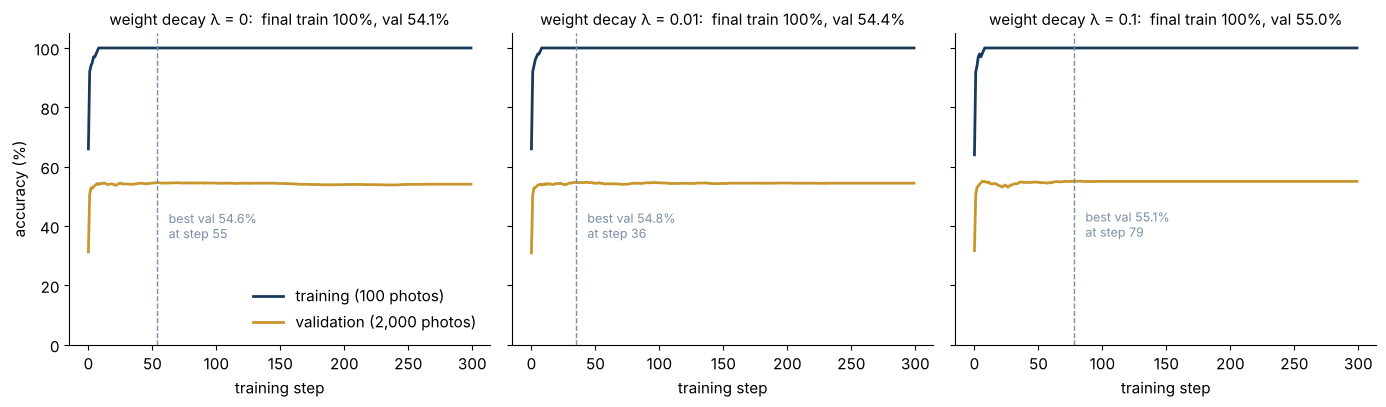

In [20]:
idx10 = subset(10)
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2), sharey=True)
for ax, wd in zip(axes, (0.0, 1e-2, 1e-1)):
    _, hist = train_head(f_train[idx10], y_train[idx10], steps=300, wd=wd, f_eval=f_val, y_eval=y_val)
    tr = [100 * h[0] for h in hist]; va = [100 * h[1] for h in hist]
    best = int(np.argmax(va))
    ax.plot(tr, color=NAVY, lw=2, label="training (100 photos)")
    ax.plot(va, color=GOLD, lw=2, label="validation (2,000 photos)")
    ax.axvline(best, color=GREY, ls="--", lw=1)
    ax.annotate(f"best val {va[best]:.1f}%\nat step {best + 1}", (best, va[best]), xytext=(8, -40),
                textcoords="offset points", fontsize=9, color=GREY)
    ax.set_title(f"weight decay λ = {wd:g}:  final train {tr[-1]:.0f}%, val {va[-1]:.1f}%", fontsize=11)
    ax.set_xlabel("training step"); ax.set_ylim(0, 105)
    print(f"λ = {wd:<5g} final: train {tr[-1]:5.1f}%  val {va[-1]:5.1f}%   best val {va[best]:.1f}% at step {best + 1}")
axes[0].set_ylabel("accuracy (%)"); axes[0].legend(loc="lower right", frameon=False)
plt.tight_layout(); plt.show()

**Weight decay by hand** (check of the slide): w = 2, gradient g = 0.5, η = 0.1, λ = 0.1.

In [21]:
w, g, eta, lam = 2.0, 0.5, 0.1, 0.1
print(f"no decay:   w <- {w} - {eta} x {g} = {w - eta * g:.3f}")
print(f"with decay: w <- {w} - {eta} x ({g} + {lam} x {w}) = {w - eta * (g + lam * w):.3f}")

# the same step done by PyTorch (SGD's weight_decay adds lam * w to the gradient)
p = torch.tensor([w], requires_grad=True)
opt = torch.optim.SGD([p], lr=eta, weight_decay=lam)
p.grad = torch.tensor([g]); opt.step()
print("PyTorch SGD(weight_decay=0.1):", round(p.item(), 3))

no decay:   w <- 2.0 - 0.1 x 0.5 = 1.950
with decay: w <- 2.0 - 0.1 x (0.5 + 0.1 x 2.0) = 1.930
PyTorch SGD(weight_decay=0.1): 1.93


**Augmentation and feature extraction.** Add the features of each training photo's left-right
mirror image: twice the examples for free. Expect a small gain: a mirrored photo's features are
almost the same as the original's. Augmentation matters most when the network's own weights
learn (fine-tuning in §7 augments on the fly, as AL7 did).

In [22]:
for n in (10, 100):
    idx = subset(n)
    f_flip = features(D["x_train"][idx][:, :, ::-1].copy())                 # mirrored photos
    head, _ = train_head(torch.cat([f_train[idx], f_flip]), np.concatenate([y_train[idx]] * 2))
    print(f"n = {n:3d}: plain {RESULTS['feature extraction'][n]:.1%}   + mirrored copies {head_acc(head, f_test, y_test):.1%}")

n =  10: plain 53.8%   + mirrored copies 54.5%


n = 100: plain 66.7%   + mirrored copies 67.3%


## 10 · Augmentation for air photos

Which changes leave the **label** the same? For CIFAR, a left-right flip is safe but upside-down
is not (no upside-down horses in the test set). A vertical (nadir) air photo has no "up": a
woodlot rotated 90° or mirrored is still a woodlot, so all 8 rotations and flips are safe, plus
small brightness and contrast changes (1958 prints vary a lot, L2). An **oblique** photo has a
horizon and a sky, so treat it like CIFAR: left-right flips only.

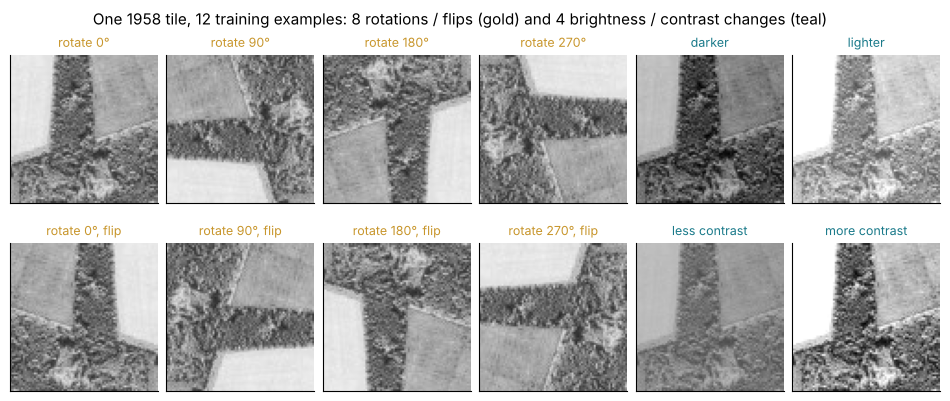

feature distance: original to its 7 rotations/flips 6.9;  to a typical other tile 9.1


In [23]:
q = where.index(("16046-19", 7, 9))                   # a field edge: easy to see the turn
tile = tiles[q]
versions = []
for k in range(4):
    r = np.rot90(tile, k)
    versions += [(r, f"rotate {90 * k}°"), (r[:, ::-1], f"rotate {90 * k}°, flip")]
fig, axes = plt.subplots(2, 6, figsize=(12, 4.4), gridspec_kw={"wspace": 0.06, "hspace": 0.25})
for a, (im, lab) in zip(axes[:, :4].T.ravel(), versions):
    a.imshow(im, cmap="gray", vmin=0, vmax=255); a.set_title(lab, fontsize=9, color=GOLD)
for a, (gain, bias, lab) in zip(axes[:, 4:].ravel(), [(1.0, -40, "darker"), (1.0, 40, "lighter"),
                                                      (0.6, 50, "less contrast"), (1.4, -50, "more contrast")]):
    a.imshow(np.clip(gain * tile.astype(np.float32) + bias, 0, 255), cmap="gray", vmin=0, vmax=255)
    a.set_title(lab, fontsize=9, color=TEAL)
for a in axes.ravel():
    a.set_xticks([]); a.set_yticks([])
plt.suptitle("One 1958 tile, 12 training examples: 8 rotations / flips (gold) and 4 brightness / contrast changes (teal)", fontsize=11)
plt.show()

# do the features agree that these are 'the same' tile?
fv = features(np.stack([v for v, _ in versions]))
others = np.where(names != "16046-19")[0]
d_same = torch.cdist(fv[:1], fv[1:]).mean().item()
d_other = torch.cdist(fv[:1], torch.tensor(f_tiles[others])).median().item()
print(f"feature distance: original to its 7 rotations/flips {d_same:.1f};  to a typical other tile {d_other:.1f}")

## 11 · The recipe for AL8 and your project

1. Load a trained network: `resnet18(weights="IMAGENET1K_V1")`.
2. Grey images: copy into 3 channels; normalise with ImageNet's mean and std; resize to ~224.
3. Replace `fc` with `nn.Linear(512, number_of_classes)`.
4. **Feature extraction first**: freeze the rest, train `fc`. This is your baseline.
5. Then **fine-tune**: unfreeze `layer4` (or everything) with a learning rate about 10–50× smaller.
6. Augment with changes that keep the label (for nadir air photos: rotations, flips, brightness).
7. Weight decay; watch validation accuracy and keep the best epoch (early stopping).
8. Test **once** at the end (AL7 Part 4).

As code (a sketch, not run here):

```python
model = torchvision.models.resnet18(weights="IMAGENET1K_V1")
model.fc = nn.Linear(512, n_classes)
for name, p in model.named_parameters():
    p.requires_grad = name.startswith(("layer4", "fc"))       # freeze all but the last stage
opt = torch.optim.SGD([p for p in model.parameters() if p.requires_grad],
                      lr=0.001, momentum=0.9, weight_decay=1e-4)
```

## 12 · Try at home

**A. By hand, then check.** A new last layer for 3 classes (woodland, field, water) on ResNet-18:
how many trainable weights? On ResNet-50 (2,048 features)? Check with `n_params(nn.Linear(...))`.

**B. 224 instead of 112.** Set `SIZE = 224`, re-run §2 and §5. How much does feature extraction
gain, and how much slower is it?

**C. PyTorch's own weights.** Replace `pretrained_resnet18()` with
`torchvision.models.resnet18(weights="IMAGENET1K_V1")` and re-run §5. Same picture?

**D. Your project's tiles.** Run §4 on tiles from your own site: are the nearest neighbours of a
building, a woodlot or a shoreline what you'd expect? That's a quick test of whether ImageNet
features suit your data before you label anything.

Next: **AL8** (Fri Nov 13): fine-tune a pre-trained ResNet on a custom dataset.
**L15** (Mon Nov 16): object detection. **Test 3** (Wed Nov 18): L12–L15.